ИНФОРМАЦИЯ О ДАТАСЕТЕ
Количество записей: 1143
Количество столбцов: 13

Названия столбцов:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'Id']

Количество пропусков:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

Количество дубликатов:
0
ФОРМИРОВАНИЕ ПРИЗНАКОВ
Количество входных признаков: 11
Признаки:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Распределение классов:
quality
3      6
4     33
5    483
6    462
7    143
8    

,max_depth,accuracy
0,2,0.585153
1,3,0.589520
2,4,0.576419
3,5,0.598253
4,6,0.576419
5,8,0.611354
6,10,0.624454
7,None,0.628821


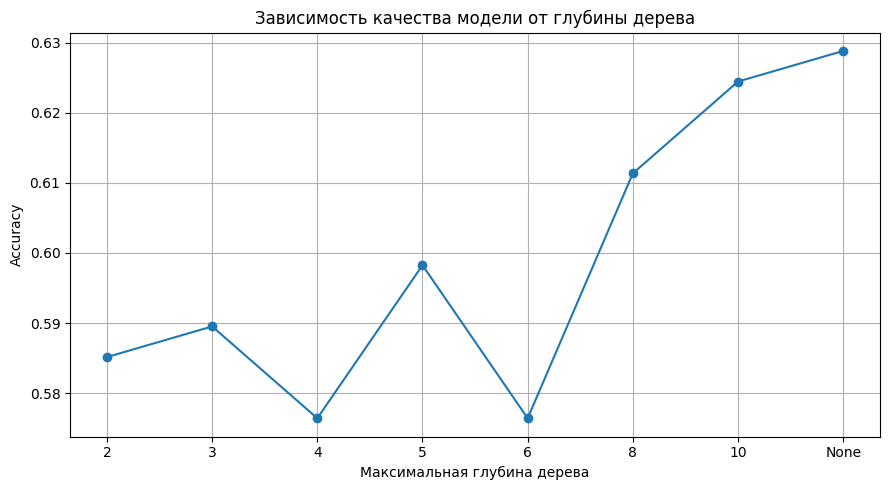

ЛУЧШАЯ КОНФИГУРАЦИЯ
max_depth = None
Accuracy = 0.6288
РЕЗУЛЬТАТЫ ИТОГОВОЙ МОДЕЛИ
Accuracy : 0.6288
Precision: 0.6208
Recall   : 0.6288
F1-score : 0.6245
ПОДРОБНЫЙ ОТЧЁТ КЛАССИФИКАЦИИ
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.17      0.14      0.15         7
           5       0.68      0.71      0.70        97
           6       0.63      0.61      0.62        92
           7       0.58      0.62      0.60        29
           8       0.00      0.00      0.00         3

    accuracy                           0.63       229
   macro avg       0.34      0.35      0.34       229
weighted avg       0.62      0.63      0.62       229



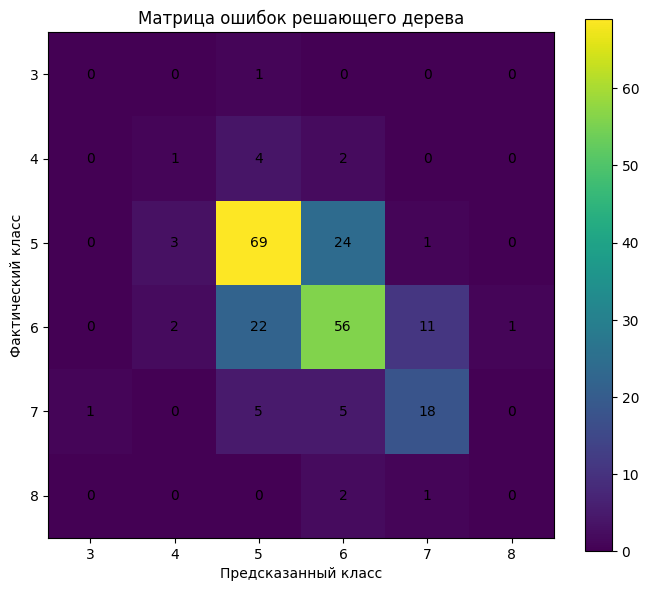

ВАЖНОСТЬ ПРИЗНАКОВ


,Признак,Важность
10,alcohol,0.167847
6,total sulfur dioxide,0.141750
1,volatile acidity,0.111832
7,density,0.097669
2,citric acid,0.084495
3,residual sugar,0.084258
8,pH,0.080833
9,sulphates,0.078402
0,fixed acidity,0.062461
4,chlorides,0.052080


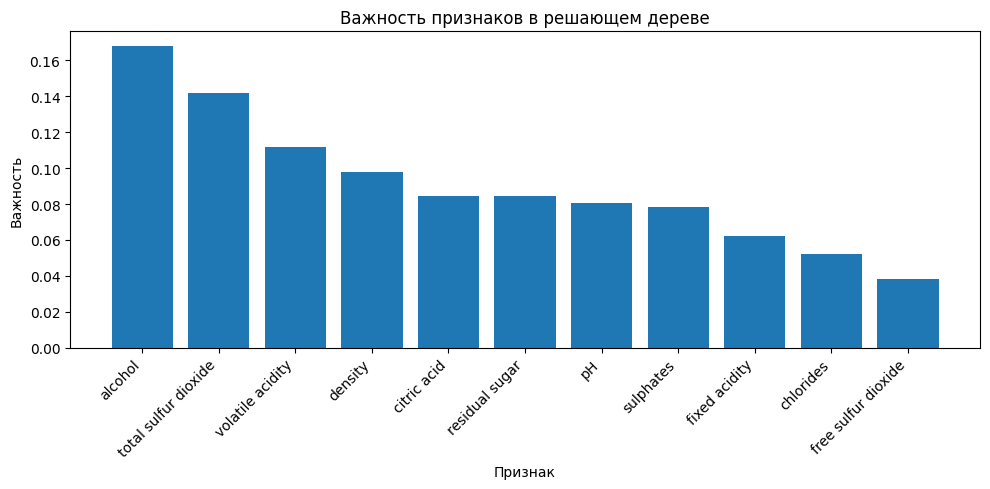

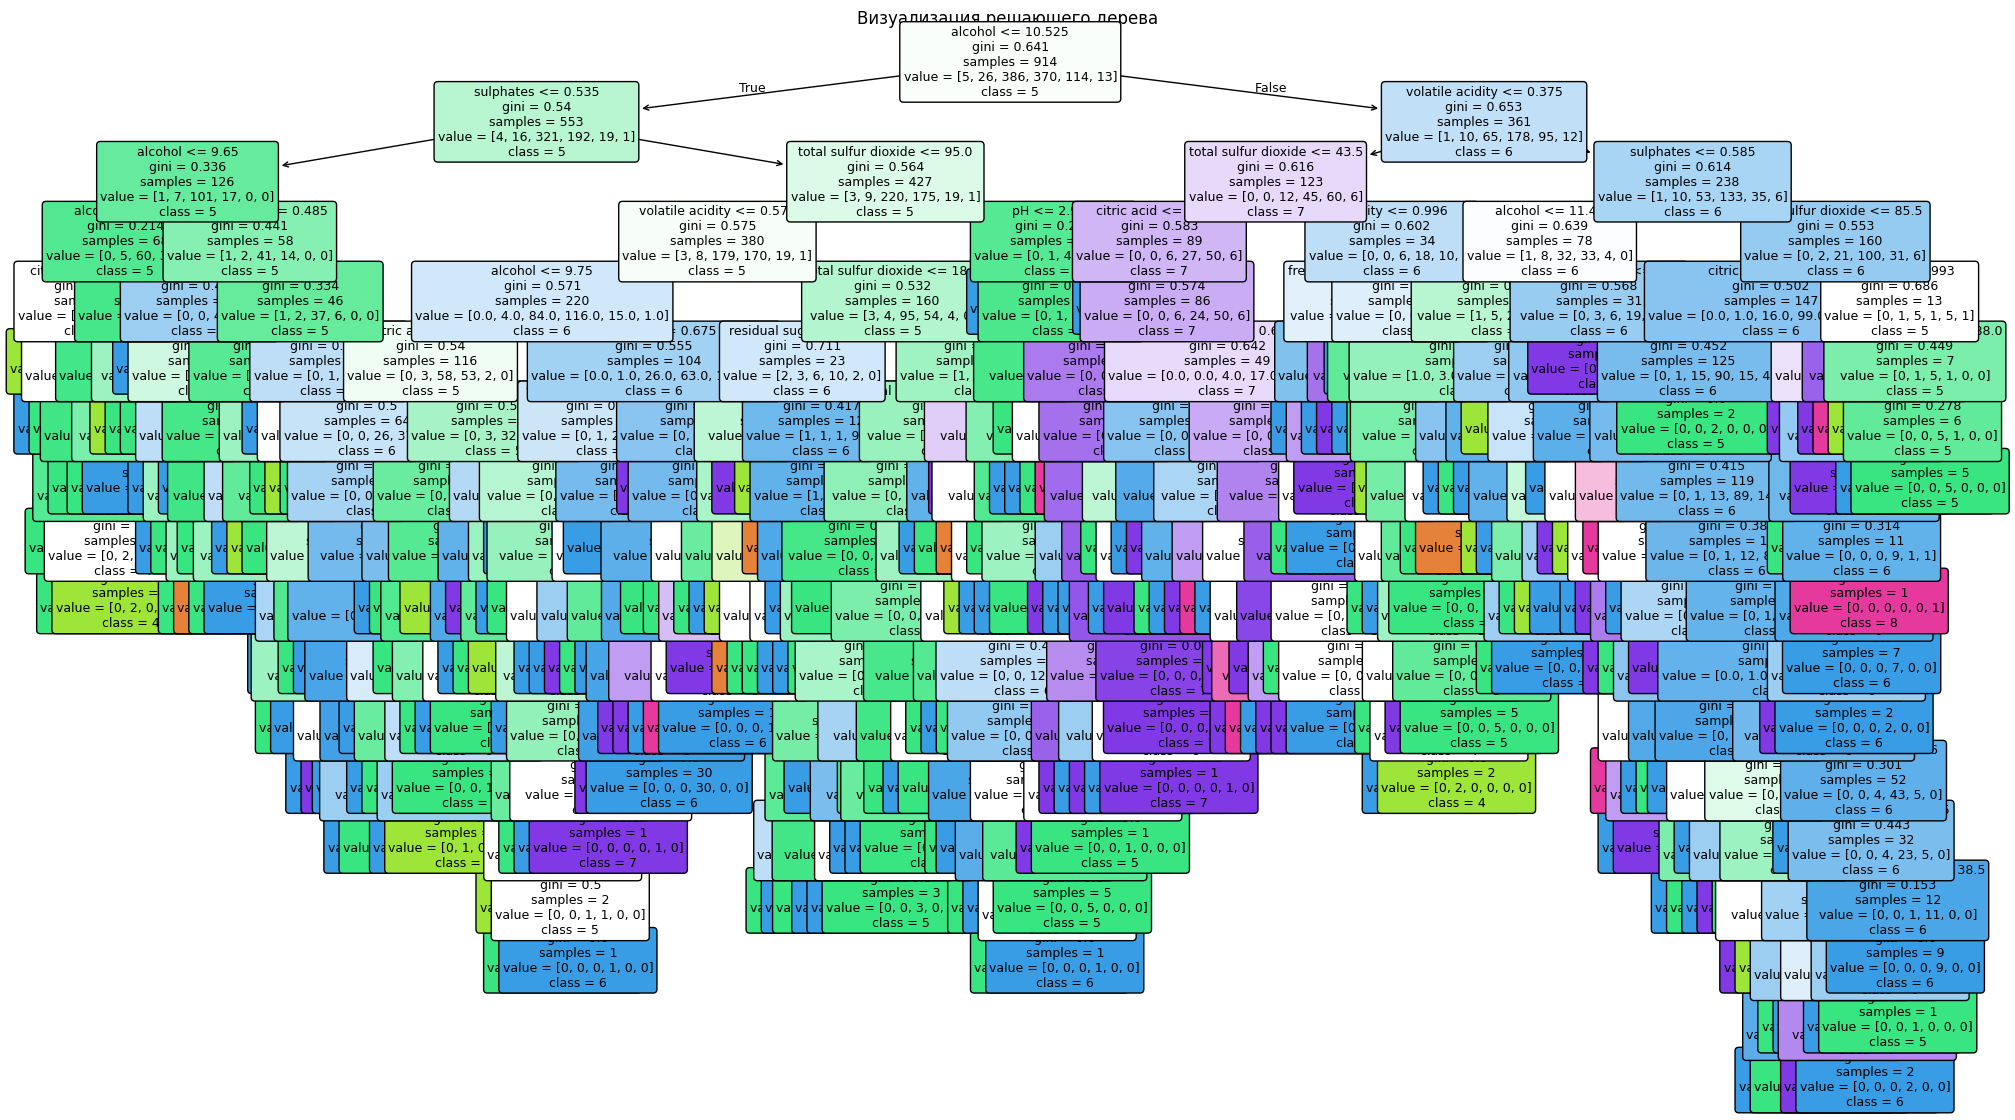

ИТОГ
Количество признаков: 11
Размер обучающей выборки: 914
Размер тестовой выборки: 229
Оптимальная глубина дерева: None
Accuracy: 0.6288
Precision: 0.6208
Recall: 0.6288
F1-score: 0.6245


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

df = pd.read_csv("WineQT.csv")

print("ИНФОРМАЦИЯ О ДАТАСЕТЕ")

print(f"Количество записей: {df.shape[0]}")
print(f"Количество столбцов: {df.shape[1]}")

print("\nНазвания столбцов:")
print(df.columns.tolist())
print("\nКоличество пропусков:")
print(df.isnull().sum())

print("\nКоличество дубликатов:")
print(df.duplicated().sum())

X = df.drop(columns=["quality", "Id"])
y = df["quality"]

print("ФОРМИРОВАНИЕ ПРИЗНАКОВ")

print(f"Количество входных признаков: {X.shape[1]}")
print("Признаки:")
print(X.columns.tolist())

print("\nРаспределение классов:")
print(y.value_counts().sort_index())

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("РАЗДЕЛЕНИЕ ДАННЫХ")

print(f"Обучающая выборка: {X_train.shape[0]} записей")
print(f"Тестовая выборка: {X_test.shape[0]} записей")

depths = [2, 3, 4, 5, 6, 8, 10, None]

results = []

for depth in depths:
    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        random_state=42
    )
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "max_depth": depth if depth is not None else "None",
        "accuracy": accuracy
    })
results_df = pd.DataFrame(results)

print("СРАВНЕНИЕ МОДЕЛЕЙ")

display(results_df)
plt.figure(figsize=(9, 5))
plt.plot(
    results_df["max_depth"].astype(str),
    results_df["accuracy"],
    marker="o"
)

plt.title("Зависимость качества модели от глубины дерева")
plt.xlabel("Максимальная глубина дерева")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

best_index = results_df["accuracy"].idxmax()
best_depth = results_df.loc[
    best_index,
    "max_depth"
]
if best_depth == "None":
    best_depth_value = None
else:
    best_depth_value = int(best_depth)

print("ЛУЧШАЯ КОНФИГУРАЦИЯ")

print(f"max_depth = {best_depth}")
print(
    f"Accuracy = "
    f"{results_df.loc[best_index, 'accuracy']:.4f}"
)

final_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=best_depth_value,
    random_state=42
)
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)
recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)
f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)
print("РЕЗУЛЬТАТЫ ИТОГОВОЙ МОДЕЛИ")

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("ПОДРОБНЫЙ ОТЧЁТ КЛАССИФИКАЦИИ")

print(
    classification_report(
        y_test,
        y_pred,
        labels=sorted(y.unique()),
        target_names=[
            str(x) for x in sorted(y.unique())
        ],
        zero_division=0
    )
)
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=sorted(y.unique())
)
plt.figure(figsize=(7, 6))
plt.imshow(cm)
plt.title("Матрица ошибок решающего дерева")
plt.xlabel("Предсказанный класс")
plt.ylabel("Фактический класс")

plt.xticks(
    range(len(sorted(y.unique()))),
    sorted(y.unique())
)
plt.yticks(
    range(len(sorted(y.unique()))),
    sorted(y.unique())
)
for i in range(len(cm)):
    for j in range(len(cm)):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )
plt.colorbar()
plt.tight_layout()
plt.show()
feature_importance = pd.DataFrame({
    "Признак": X.columns,
    "Важность": final_model.feature_importances_
}).sort_values(
    by="Важность",
    ascending=False
)

print("ВАЖНОСТЬ ПРИЗНАКОВ")

display(feature_importance)
plt.figure(figsize=(10, 5))
plt.bar(
    feature_importance["Признак"],
    feature_importance["Важность"]
)
plt.title("Важность признаков в решающем дереве")
plt.xlabel("Признак")
plt.ylabel("Важность")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()
plt.figure(figsize=(24, 14))

plot_tree(
    final_model,
    feature_names=X.columns,
    class_names=[
        str(x) for x in final_model.classes_
    ],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Визуализация решающего дерева")
plt.show()

print("ИТОГ")

print(f"Количество признаков: {X.shape[1]}")
print(f"Размер обучающей выборки: {X_train.shape[0]}")
print(f"Размер тестовой выборки: {X_test.shape[0]}")
print(f"Оптимальная глубина дерева: {best_depth}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

